# Enzymatic Degradation of Plastic with LCC_ICCG

**Structure of this File:**
1. [Library Imports](#library-imports)
2. [Data Import](#data-import)
3. [Perform Data Visualization](#perform-data-visualization)
4. [Perform Train Test Split](#perform-train-test-split)
5. [Randorm Forest Regression](#randorm-forest-regression)
6. [Gradient Boosing Regression](#gradient-boosting-regression)

**Description of the File:**  
I importet my previously curated dataset. Currently there are no outliers visible anymore. It might be beneficial to have in the future a closer look to the standard devation to figure out possible wrong measurements. I visualised the most important features with seaborn. Namely the connection of yield and selectivity with the solvent concentration. I further implemented the temperature and pH as they are also important. I did not visualise the time, because the reaction time varied according to the chose conditions.  

I performed afterwards a train test split 70/30 and set a random state to 101 for reproducibility. I trained then a random forest model with 100 estimators - this is the standard value I do not have the experience to say wheter the value is reasonable. The radom forest model performs for whatever reason very well having r2 coeffients above 0.99.
To some sort of get another view on the dataset I also used a gradient boosting regression (hope i can do this), as it is in the same family of enseble methods and after reading the documentation I though it would be worth a shot. The trained model performs similarily well but has slightly lower R2 value for the than the random foreset model.


## Dataset
Mean_TPA: concentration of TPA in &mu;M  
Mean_MHET: concentration of MHET in &mu;M  
Mean_BHET: concentration of BHET in &mu;M  
Mean_Yield: total yield in &mu;M  
Mean_Selectivity_TPA: selectivity TPA [-]  
Mean_Selectivity_MHET: selectivity MHET [-]  
Mean_Selectivity_BHET: selectivity BHET [-]  
time: reaction time in h  
substrate: absolute amount in disks  
enzyme: enzyme concentration in nM  
solvent: co-solvent added in vol%  
temperature: temeprature in deg C  





## Library Imports

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay, r2_score
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score

%matplotlib inline

# Data Import

In [8]:
data = pd.read_excel("PET_DegradationTrain_Test.xlsx")
data.head()

,family,time,substrate / disc mL-1,S,enzyme,solvent,temperature,ph,BHET,Mean_BHET,Mean_Selectivity_BHET
0,1,0.25,1,32,250.0,0,50,10,0.001758,0.013970,10.465781
1,1,0.25,2,64,250.0,0,50,10,0.003396,0.013490,10.864840
2,1,0.25,4,128,62.5,0,50,10,0.004066,0.008075,9.698994
3,1,0.25,4,128,125.0,0,50,10,0.005098,0.010127,8.257459
4,1,0.25,4,128,250.0,0,50,10,0.006266,0.012446,10.011694


In [9]:
print(data.columns)

Index(['family', 'time', 'substrate / disc mL-1', 'S', 'enzyme', 'solvent',
       'temperature', 'ph', 'BHET', 'Mean_BHET', 'Mean_Selectivity_BHET'],
      dtype='object')


## Perform Train Test Split

In [10]:
X=data[["S","time","enzyme", "solvent", "temperature", "ph"]]
#y=data["Mean_Selectivity_BHET"]
y=data["Mean_BHET"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)

In [11]:
X_train.count()

S              162
time           162
enzyme         162
solvent        162
temperature    162
ph             162
dtype: int64

## Gaussian process Regression

In [12]:
# Fitting GP Regression to the Training set

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, DotProduct

kernel = Matern(nu=3, length_scale_bounds=(1e-04, 100000.0)) +DotProduct(sigma_0=1.0, sigma_0_bounds=(1e-04, 100000.0))
model = GaussianProcessRegressor(kernel=kernel, alpha=0.001, normalize_y = True, random_state = 42, n_restarts_optimizer=0)
model.fit(X_train, y_train)


#Measure the R2 for training and test set
model_score = model.score(X_train,y_train)
print("The training R2 is: ", model.score(X_train, y_train))
print("The test R2 is: ", model.score(X_test, y_test))

from sklearn.metrics import mean_squared_error
from math import sqrt


y_predicted = model.predict(X_test)
y_predicted_train = model.predict(X_train)

# The mean squared error & Variance
print("MSE: %.2f"% mean_squared_error(y_test, y_predicted))
print("RMSE of test set: %.2f"% sqrt(mean_squared_error(y_test, y_predicted)))
print("RMSE of train set: %.2f"% sqrt(mean_squared_error(y_train, y_predicted_train)))


#k-cross validation
from sklearn.model_selection import cross_val_score
accuracies = cross_val_score(estimator = model, X = X_train, y= y_train, cv=5)
print("The mean accuracy is: ", accuracies.mean())



The training R2 is:  0.9999427509981259
The test R2 is:  0.968542125297114
MSE: 0.06
RMSE of test set: 0.24
RMSE of train set: 0.01
The mean accuracy is:  0.7922292542298166


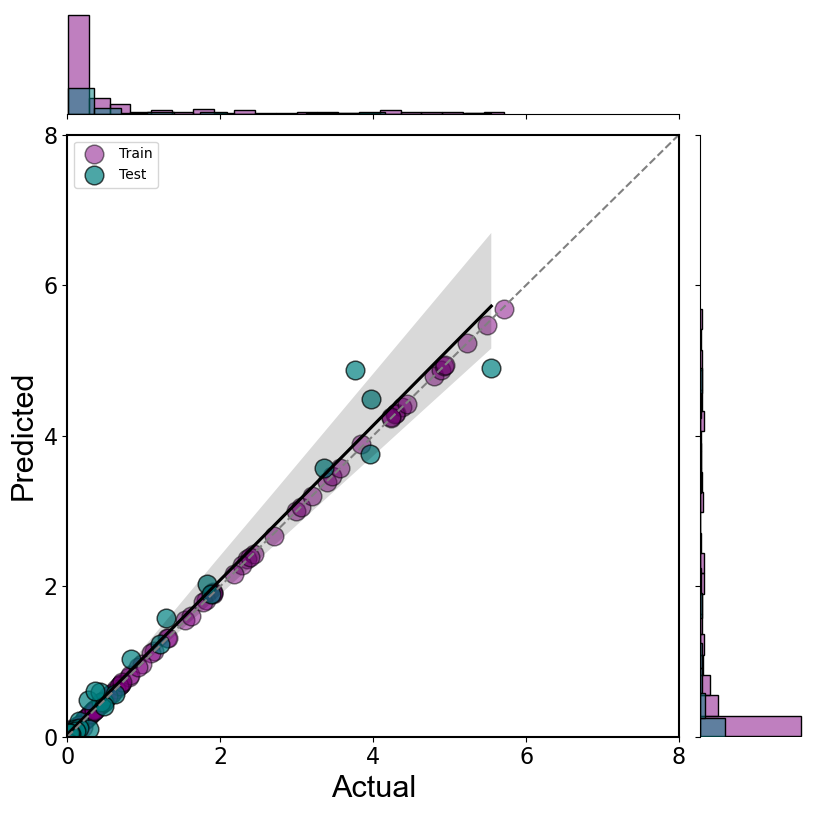

In [14]:
from sklearn.metrics import mean_squared_error, r2_score
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# User-controlled plotting vars
# -----------------------------
x_min, x_max = 0, 8
y_min, y_max = 0, 8
tick_interval = 2

train_color = 'purple'
test_color = 'teal'
reg_line_color = 'black'

train_circle_size = 180
test_circle_size = 180

train_alpha = 0.5
test_alpha = 0.7

label_fontsize = 22
tick_fontsize = 16

# -----------------------------
# Predictions
# -----------------------------
pp_tr = model.predict(X_train)
pp_te = model.predict(X_test)

# -----------------------------
# Joint plot
# -----------------------------
g = sns.JointGrid(x=y_test, y=pp_te, height=8)

# Scatter points
sns.scatterplot(
    x=y_train, y=pp_tr,
    s=train_circle_size,
    color=train_color,
    edgecolor='black',
    alpha=train_alpha,
    ax=g.ax_joint,
    label='Train'
)

sns.scatterplot(
    x=y_test, y=pp_te,
    s=test_circle_size,
    color=test_color,
    edgecolor='black',
    alpha=test_alpha,
    ax=g.ax_joint,
    label='Test'
)

# Regression line for test set
sns.regplot(
    x=y_test, y=pp_te,
    scatter=False,
    color=reg_line_color,
    ax=g.ax_joint
)

# 1:1 reference line
g.ax_joint.plot(
    [x_min, x_max], [y_min, y_max],
    linestyle='--', color='gray', linewidth=1.5
)

# Axis labels
g.set_axis_labels("Actual", "Predicted", fontsize=label_fontsize, fontname='Arial')

# Marginal histograms
sns.histplot(x=y_train, ax=g.ax_marg_x, color=train_color, alpha=0.5)
sns.histplot(x=y_test, ax=g.ax_marg_x, color=test_color, alpha=0.5)

sns.histplot(y=pp_tr, ax=g.ax_marg_y, color=train_color, alpha=0.5)
sns.histplot(y=pp_te, ax=g.ax_marg_y, color=test_color, alpha=0.5)

# -----------------------------
# Axis limits and ticks
# -----------------------------
g.ax_joint.set_xlim(x_min, x_max)
g.ax_joint.set_ylim(y_min, y_max)

g.ax_joint.set_xticks(np.arange(x_min, x_max + tick_interval, tick_interval))
g.ax_joint.set_yticks(np.arange(y_min, y_max + tick_interval, tick_interval))

# -----------------------------
# Make x and y axes intersect at 0
# while keeping full border visible
# -----------------------------
ax = g.ax_joint

# Move left and bottom spines to zero
ax.spines['left'].set_position(('data', 0))
ax.spines['bottom'].set_position(('data', 0))

# Keep full border
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)

# Make all spines thicker if desired
for spine in ax.spines.values():
    spine.set_linewidth(1.5)

# Ensure ticks stay on bottom/left axes
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')

# Tick font size
ax.tick_params(axis='both', labelsize=tick_fontsize)

# Legend
ax.legend()

plt.savefig("yield.svg", format="svg", bbox_inches="tight", dpi=300)

plt.show()

## Yield SHAP

  0%|          | 0/162 [00:00<?, ?it/s]

C:\Users\msuva\AppData\Local\Temp\ipykernel_24360\213707984.py:72: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


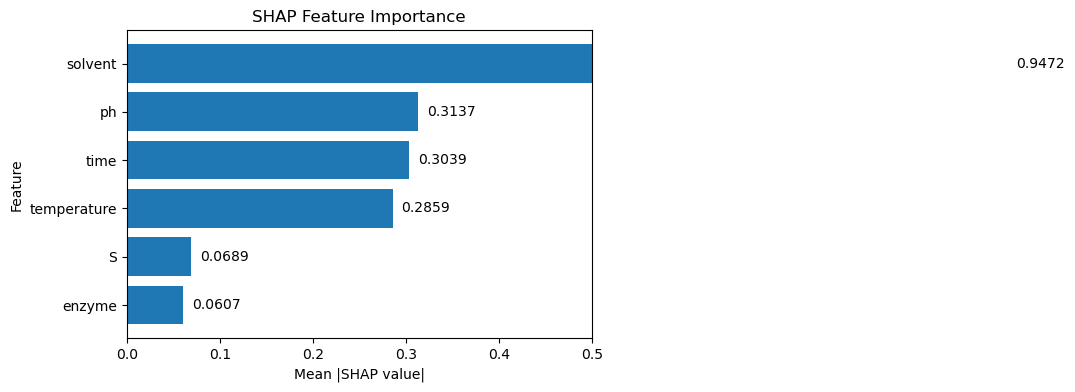

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import shap

# Numeric SHAP axis (horizontal axis in barh)
X_AXIS_MIN = 0.0
X_AXIS_MAX = 0.5
X_TICK_INTERVAL = 0.1


# Create KernelExplainer
X_background = shap.sample(X_train, 50, random_state=42)
explainer = shap.KernelExplainer(model.predict, X_background)

# Calculate SHAP values
shap_values = explainer.shap_values(X_train)

# If output is single-target regression, shap_values is usually 2D: (n_samples, n_features)
# If it comes as a list, take the first output
if isinstance(shap_values, list):
    shap_values_to_use = shap_values[0]
else:
    shap_values_to_use = shap_values

# Compute mean absolute SHAP value per feature
mean_abs_shap = np.abs(shap_values_to_use).mean(axis=0)

# Build a dataframe for sorting
shap_df = pd.DataFrame({
    "Feature": X_train.columns,
    "MeanAbsSHAP": mean_abs_shap
})

# Sort and keep top features
max_display = 12
shap_df = shap_df.sort_values("MeanAbsSHAP", ascending=True).tail(max_display)

# Plot
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.barh(shap_df["Feature"], shap_df["MeanAbsSHAP"])

# Add numeric labels next to bars
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.01 * shap_df["MeanAbsSHAP"].max(),   # small offset
        bar.get_y() + bar.get_height() / 2,
        f"{width:.4f}",
        va="center"
    )

ax.set_xlabel("Mean |SHAP value|")
ax.set_ylabel("Feature")
ax.set_title("SHAP Feature Importance")

# -------------------------
# AXIS CONTROLS
# -------------------------
# X-axis = SHAP magnitude axis
if X_AXIS_MIN is not None or X_AXIS_MAX is not None:
    current_xlim = ax.get_xlim()
    ax.set_xlim(
        X_AXIS_MIN if X_AXIS_MIN is not None else current_xlim[0],
        X_AXIS_MAX if X_AXIS_MAX is not None else current_xlim[1]
    )

if X_TICK_INTERVAL is not None:
    ax.xaxis.set_major_locator(MultipleLocator(X_TICK_INTERVAL))

plt.tight_layout()

#plt.savefig("yieldSHAP.svg", format="svg", bbox_inches="tight", dpi=300)
plt.show()

## Selectivity SHAP

Using 162 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


  0%|          | 0/162 [00:00<?, ?it/s]

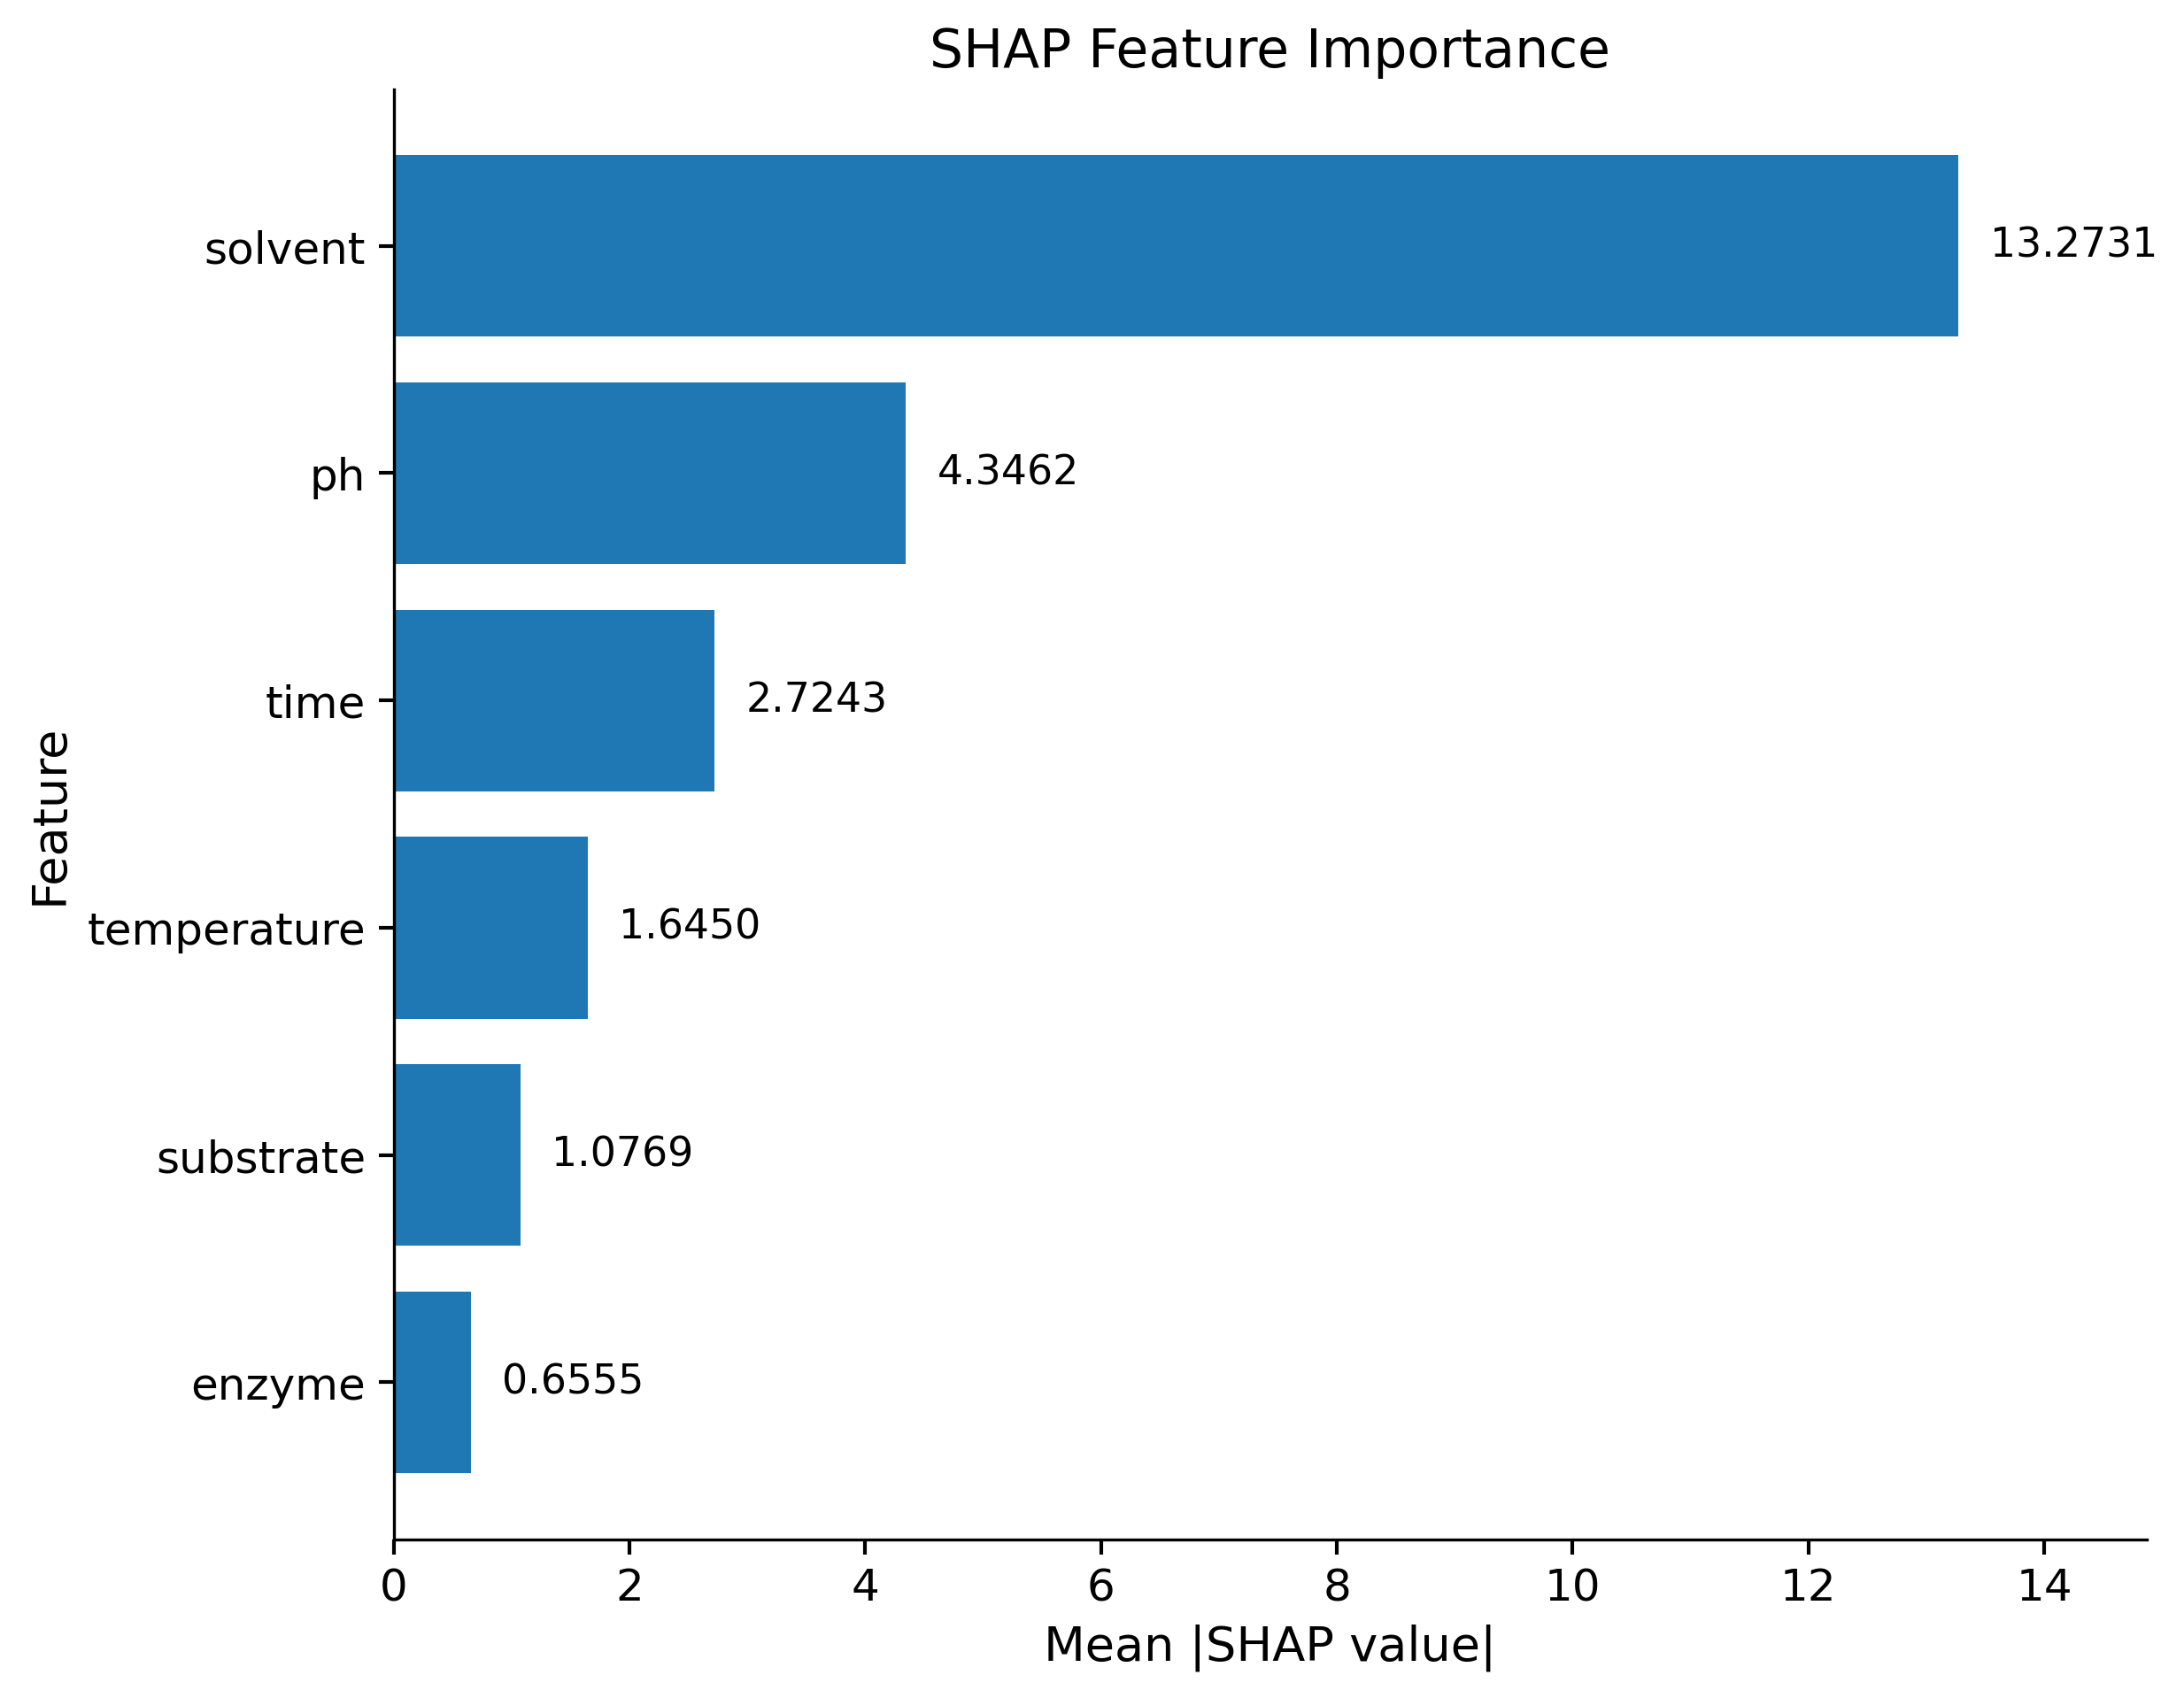

In [10]:
from matplotlib.ticker import MultipleLocator
import shap

# =========================
# USER CONTROLS
# =========================
MAX_DISPLAY = 12

# Figure controls
FIGSIZE = (11, 7)
DPI = 300
BAR_COLOR = "#1f77b4"
LABEL_DECIMALS = 4
FONT_SIZE = 12
VALUE_FONT_SIZE = 11

# Axis controls for SHAP magnitude axis
X_AXIS_MIN = 0.0
X_AXIS_MAX = None          # set e.g. 0.25 if you want fixed max
X_TICK_INTERVAL = None     # set e.g. 0.05 if desired

# Y-axis controls for feature rows
Y_AXIS_MIN = None
Y_AXIS_MAX = None
Y_TICK_INTERVAL = 1

# Optional: shorten long feature names
SHORTEN_NAMES = False
MAX_NAME_LEN = 25

# =========================
# SHAP
# =========================
explainer = shap.KernelExplainer(model.predict, X_train)
shap_values = explainer.shap_values(X_train)

if isinstance(shap_values, list):
    shap_values_to_use = shap_values[0]
else:
    shap_values_to_use = shap_values

mean_abs_shap = np.abs(shap_values_to_use).mean(axis=0)

shap_df = pd.DataFrame({
    "Feature": X_train.columns,
    "MeanAbsSHAP": mean_abs_shap
})

shap_df = (
    shap_df.sort_values("MeanAbsSHAP", ascending=True)
           .tail(MAX_DISPLAY)
           .reset_index(drop=True)
)

if SHORTEN_NAMES:
    shap_df["Feature"] = shap_df["Feature"].apply(
        lambda x: x if len(str(x)) <= MAX_NAME_LEN else str(x)[:MAX_NAME_LEN] + "..."
    )

# =========================
# PLOT
# =========================
plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.labelsize": FONT_SIZE + 1,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
})

fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI)

bars = ax.barh(
    shap_df["Feature"],
    shap_df["MeanAbsSHAP"],
    color=BAR_COLOR
)

# Give extra space on the right for value labels
max_val = shap_df["MeanAbsSHAP"].max()
text_offset = 0.02 * max_val if max_val > 0 else 0.01

# Add numeric labels next to bars
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + text_offset,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.{LABEL_DECIMALS}f}",
        va="center",
        ha="left",
        fontsize=VALUE_FONT_SIZE
    )

ax.set_xlabel("Mean |SHAP value|")
ax.set_ylabel("Feature")
ax.set_title("SHAP Feature Importance")

# Clean publication-style axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", length=4, width=1)

# X-axis control
if X_AXIS_MAX is None:
    ax.set_xlim(X_AXIS_MIN, max_val + 6 * text_offset)
else:
    ax.set_xlim(X_AXIS_MIN, X_AXIS_MAX)

if X_TICK_INTERVAL is not None:
    ax.xaxis.set_major_locator(MultipleLocator(X_TICK_INTERVAL))

# Y-axis control
if Y_AXIS_MIN is not None or Y_AXIS_MAX is not None:
    current_ylim = ax.get_ylim()
    ax.set_ylim(
        Y_AXIS_MIN if Y_AXIS_MIN is not None else current_ylim[0],
        Y_AXIS_MAX if Y_AXIS_MAX is not None else current_ylim[1]
    )

if Y_TICK_INTERVAL is not None:
    ax.yaxis.set_major_locator(MultipleLocator(Y_TICK_INTERVAL))

# Manually adjust margins instead of relying only on tight_layout
plt.subplots_adjust(left=0.35, right=0.95, top=0.90, bottom=0.12)

plt.savefig("selectivitySHAP.svg", format="svg", bbox_inches="tight", dpi=300)

plt.show()

## TEST ON PHL7

In [39]:
df = pd.read_excel("PET_DegradationTrain_Test.xlsx", sheet_name="PHL7", index_col=0)
df.head()

,time,substrate,enzyme,solvent,temperature,ph,Mean_BHET,Mean_Selectivity_BHET
expt,,,,,,,,
Opt60.0.1,2,1,200,0,60.0,8.5,0.07651,0.22
Opt60.5.1,2,1,200,5,60.0,8.5,0.09394,0.22
Opt60.10.1,2,1,200,10,60.0,8.5,0.14538,0.22
Opt60.15.1,2,1,200,15,60.0,8.5,0.08961,0.22
Opt60.20.1,2,1,200,20,60.0,8.5,0.06500,0.22


In [40]:
# ---------------------------------------------------------
# Define X and y
# Replace 'target' with your actual target column name
# ---------------------------------------------------------
X=df[["time","substrate",	"enzyme", "solvent", "temperature", "ph"]]
y = df['Mean_BHET']

# Keep only numeric columns if needed
X = X.select_dtypes(include=[np.number])

# If y is a pandas Series, keep as is
# If needed, convert:
# y = y.astype(float)

# =========================================================
# 2. Define kernel and model function
# =========================================================
def get_gpr_model():
    kernel = Matern(
        nu=2.5,
        length_scale_bounds=(1e-07, 100000.0)
    ) + DotProduct(
        sigma_0=1.0,
        sigma_0_bounds=(1e-07, 100000.0)
    )

    model = GaussianProcessRegressor(
        kernel=kernel,
        alpha=0.01,
        normalize_y=True,
        random_state=42,
        n_restarts_optimizer=0
    )
    return model

# =========================================================
# 3. Helper function to compute metrics
# =========================================================
def compute_metrics(y_train, y_train_pred, y_test, y_test_pred, label=""):
    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)
    train_rmse = sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = sqrt(mean_squared_error(y_test, y_test_pred))

    print(f"\n===== {label} =====")
    print("Train R2: %.3f" % train_r2)
    print("Test R2: %.3f" % test_r2)
    print("Train RMSE: %.3f" % train_rmse)
    print("Test RMSE: %.3f" % test_rmse)

    return {
        "Scenario": label,
        "Train_R2": train_r2,
        "Test_R2": test_r2,
        "Train_RMSE": train_rmse,
        "Test_RMSE": test_rmse
    }

# =========================================================
# 4. 80:20 train-test split
# =========================================================
X_train_80, X_test_20, y_train_80, y_test_20 = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model_80_20 = get_gpr_model()
model_80_20.fit(X_train_80, y_train_80)

y_train_pred_80 = model_80_20.predict(X_train_80)
y_test_pred_20 = model_80_20.predict(X_test_20)

result_80_20 = compute_metrics(
    y_train_80, y_train_pred_80,
    y_test_20, y_test_pred_20,
    label="80:20 Train-Test Split"
)

# =========================================================
# 6. Leave-One-Out Cross Validation
# =========================================================
loo = LeaveOneOut()

y_true_loo = []
y_pred_loo = []
y_train_all_loo = []
y_train_pred_all_loo = []

fold_results = []

for fold, (train_idx, test_idx) in enumerate(loo.split(X), start=1):
    X_train_loo = X.iloc[train_idx]
    X_test_loo = X.iloc[test_idx]
    y_train_loo = y.iloc[train_idx]
    y_test_loo = y.iloc[test_idx]

    model_loo = get_gpr_model()
    model_loo.fit(X_train_loo, y_train_loo)

    # train prediction for this fold
    y_train_pred_loo = model_loo.predict(X_train_loo)

    # left-out test prediction
    y_test_pred_loo = model_loo.predict(X_test_loo)

    # store train metrics data
    y_train_all_loo.extend(y_train_loo.tolist())
    y_train_pred_all_loo.extend(y_train_pred_loo.tolist())

    # store test metrics data
    y_true_loo.extend(y_test_loo.tolist())
    y_pred_loo.extend(y_test_pred_loo.tolist())

    fold_rmse = sqrt(mean_squared_error(y_test_loo, y_test_pred_loo))

    fold_results.append({
        "Fold": fold,
        "Test_Actual": y_test_loo.values[0],
        "Test_Predicted": y_test_pred_loo[0],
        "Test_RMSE": fold_rmse
    })

# Overall LOO metrics
loo_train_r2 = r2_score(y_train_all_loo, y_train_pred_all_loo)
loo_train_rmse = sqrt(mean_squared_error(y_train_all_loo, y_train_pred_all_loo))

loo_test_r2 = r2_score(y_true_loo, y_pred_loo)
loo_test_rmse = sqrt(mean_squared_error(y_true_loo, y_pred_loo))

print("\n===== Leave-One-Out Cross Validation =====")
print("Train R2: %.3f" % loo_train_r2)
print("Test R2: %.3f" % loo_test_r2)
print("Train RMSE: %.3f" % loo_train_rmse)
print("Test RMSE: %.3f" % loo_test_rmse)

result_loo = {
    "Scenario": "Leave-One-Out CV",
    "Train_R2": loo_train_r2,
    "Test_R2": loo_test_r2,
    "Train_RMSE": loo_train_rmse,
    "Test_RMSE": loo_test_rmse
}

# =========================================================
# 7. Summary table
# =========================================================
summary_df = pd.DataFrame([result_80_20, result_loo])

print("\n===== Summary of Model Performance =====")
print(summary_df)

# Optional: save summary
# summary_df.to_csv("GPR_performance_summary.csv", index=False)

# Optional: save LOO fold predictions
# fold_results_df = pd.DataFrame(fold_results)
# fold_results_df.to_csv("GPR_LOO_fold_predictions.csv", index=False)


===== 80:20 Train-Test Split =====
Train R2: 1.000
Test R2: 0.687
Train RMSE: 0.001
Test RMSE: 0.022

===== Leave-One-Out Cross Validation =====
Train R2: 0.999
Test R2: 0.787
Train RMSE: 0.001
Test RMSE: 0.018

===== Summary of Model Performance =====
                 Scenario  Train_R2   Test_R2  Train_RMSE  Test_RMSE
0  80:20 Train-Test Split  0.999574  0.686745    0.000825   0.022174
1        Leave-One-Out CV  0.999309  0.786994    0.001048   0.018403


## Tranfer learning

In [41]:
# =========================================================
# Assumptions
# ---------------------------------------------------------
# 1. LCC dataset is in dataframe: data
# 2. PHL7 dataset is in dataframe: df
# 3. Both dataframes contain the same feature columns and the same target column
# 4. Replace 'target' below with your actual target column name
# =========================================================

target_col = 'Mean_BHET'   # <-- replace with your actual target column name

# =========================================================
# Prepare source (LCC) and target (PHL7) data
# =========================================================
X_lcc = data.drop(columns=[target_col]).select_dtypes(include=[np.number]).copy()
y_lcc = data[target_col].copy()

X_phl7 = df.drop(columns=[target_col]).select_dtypes(include=[np.number]).copy()
y_phl7 = df[target_col].copy()

# Ensure same feature columns and same order
common_cols = X_lcc.columns.intersection(X_phl7.columns)
X_lcc = X_lcc[common_cols]
X_phl7 = X_phl7[common_cols]

print("LCC shape:", X_lcc.shape, y_lcc.shape)
print("PHL7 shape:", X_phl7.shape, y_phl7.shape)
print("Number of common features:", len(common_cols))

LCC shape: (440, 7) (440,)
PHL7 shape: (30, 7) (30,)
Number of common features: 7


In [42]:
# =========================================================
# Define kernel and model
# =========================================================
def get_gpr_model():
    kernel = Matern(
        nu=2.5,
        length_scale_bounds=(1e-07, 100000.0)
    ) + DotProduct(
        sigma_0=1.0,
        sigma_0_bounds=(1e-07, 100000.0)
    )

    model = GaussianProcessRegressor(
        kernel=kernel,
        alpha=0.006,
        normalize_y=True,
        random_state=42,
        n_restarts_optimizer=0
    )
    return model

# =========================================================
# Experiment settings
# ---------------------------------------------------------
# 5 iterations each for augmentation sizes 6, 7, and 8
# =========================================================
augment_sizes = [6, 7, 8]
n_repeats = 5
base_seed = 42

results = []
holdout_predictions_all = []

# =========================================================
# Run few-shot augmentation experiments
# =========================================================
for n_aug in augment_sizes:
    print("\n" + "=" * 60)
    print(f"Running augmentation size = {n_aug}")
    print("=" * 60)

    for rep in range(n_repeats):
        seed = base_seed + 100 * n_aug + rep
        rng = np.random.RandomState(seed)

        # Randomly sample PHL7 points to augment training
        aug_idx = rng.choice(X_phl7.index, size=n_aug, replace=False)
        holdout_idx = X_phl7.index.difference(aug_idx)

        X_aug = X_phl7.loc[aug_idx]
        y_aug = y_phl7.loc[aug_idx]

        X_holdout = X_phl7.loc[holdout_idx]
        y_holdout = y_phl7.loc[holdout_idx]

        # Training set = full LCC + selected PHL7 augmentation points
        X_train = pd.concat([X_lcc, X_aug], axis=0)
        y_train = pd.concat([y_lcc, y_aug], axis=0)

        # Fit model
        model = get_gpr_model()
        model.fit(X_train, y_train)

        # Predict
        y_train_pred = model.predict(X_train)
        y_holdout_pred = model.predict(X_holdout)

        # Metrics
        train_r2 = r2_score(y_train, y_train_pred)
        holdout_r2 = r2_score(y_holdout, y_holdout_pred)
        train_rmse = sqrt(mean_squared_error(y_train, y_train_pred))
        holdout_rmse = sqrt(mean_squared_error(y_holdout, y_holdout_pred))

        results.append({
            'Augment_Size': n_aug,
            'Repeat': rep + 1,
            'Random_Seed': seed,
            'Train_Size': len(X_train),
            'Holdout_Size': len(X_holdout),
            'Train_R2': train_r2,
            'Holdout_R2': holdout_r2,
            'Train_RMSE': train_rmse,
            'Holdout_RMSE': holdout_rmse
        })

        # Store holdout predictions if needed later
        temp_pred = pd.DataFrame({
            'Augment_Size': n_aug,
            'Repeat': rep + 1,
            'Index': y_holdout.index,
            'Actual': y_holdout.values,
            'Predicted': y_holdout_pred
        })
        holdout_predictions_all.append(temp_pred)

        print(f"Augment = {n_aug}, Repeat = {rep+1}")
        print("Train R2: %.3f" % train_r2)
        print("Holdout R2: %.3f" % holdout_r2)
        print("Train RMSE: %.3f" % train_rmse)
        print("Holdout RMSE: %.3f" % holdout_rmse)
        print("-" * 40)

# =========================================================
# Collect results
# =========================================================
results_df = pd.DataFrame(results)
holdout_predictions_df = pd.concat(holdout_predictions_all, axis=0, ignore_index=True)

print("\n" + "=" * 60)
print("All experiment results")
print("=" * 60)
print(results_df)

# =========================================================
# Average performance for each augmentation size
# =========================================================
summary_by_aug = results_df.groupby('Augment_Size').agg({
    'Train_R2': ['mean', 'std'],
    'Holdout_R2': ['mean', 'std'],
    'Train_RMSE': ['mean', 'std'],
    'Holdout_RMSE': ['mean', 'std']
}).round(4)

print("\n" + "=" * 60)
print("Average performance by augmentation size")
print("=" * 60)
print(summary_by_aug)

# =========================================================
# Overall average across all 15 runs (5 repeats × 3 augment sizes)
# =========================================================
overall_summary = results_df[['Train_R2', 'Holdout_R2', 'Train_RMSE', 'Holdout_RMSE']].agg(['mean', 'std']).round(4)

print("\n" + "=" * 60)
print("Overall average across all augmentation experiments")
print("=" * 60)
print(overall_summary)

"""# =========================================================
# Optional: save outputs
# =========================================================
results_df.to_csv("PHL7_augmentation_results_all_runs.csv", index=False)
holdout_predictions_df.to_csv("PHL7_augmentation_holdout_predictions.csv", index=False)

# Flatten multi-index columns before saving summary
summary_by_aug_save = summary_by_aug.copy()
summary_by_aug_save.columns = ['_'.join(col) for col in summary_by_aug_save.columns]
summary_by_aug_save = summary_by_aug_save.reset_index()
summary_by_aug_save.to_csv("PHL7_augmentation_summary_by_augsize.csv", index=False)

overall_summary.to_csv("PHL7_augmentation_overall_summary.csv")

print("\nFiles saved:")
print("- PHL7_augmentation_results_all_runs.csv")
print("- PHL7_augmentation_holdout_predictions.csv")
print("- PHL7_augmentation_summary_by_augsize.csv")
print("- PHL7_augmentation_overall_summary.csv")"""



Running augmentation size = 6
Augment = 6, Repeat = 1
Train R2: 0.999
Holdout R2: -101.670
Train RMSE: 0.042
Holdout RMSE: 0.421
----------------------------------------
Augment = 6, Repeat = 2
Train R2: 0.999
Holdout R2: -27.183
Train RMSE: 0.041
Holdout RMSE: 0.213
----------------------------------------
Augment = 6, Repeat = 3
Train R2: 0.999
Holdout R2: -18.980
Train RMSE: 0.041
Holdout RMSE: 0.189
----------------------------------------
Augment = 6, Repeat = 4
Train R2: 0.999
Holdout R2: -105.158
Train RMSE: 0.042
Holdout RMSE: 0.429
----------------------------------------
Augment = 6, Repeat = 5
Train R2: 0.999
Holdout R2: -57.865
Train RMSE: 0.041
Holdout RMSE: 0.300
----------------------------------------

Running augmentation size = 7


C:\Users\msuva\anaconda3\Lib\site-packages\sklearn\gaussian_process\_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 13 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


Augment = 7, Repeat = 1
Train R2: 0.999
Holdout R2: -16.679
Train RMSE: 0.041
Holdout RMSE: 0.181
----------------------------------------
Augment = 7, Repeat = 2
Train R2: 0.999
Holdout R2: -39.699
Train RMSE: 0.041
Holdout RMSE: 0.275
----------------------------------------
Augment = 7, Repeat = 3
Train R2: 0.999
Holdout R2: -13.831
Train RMSE: 0.041
Holdout RMSE: 0.164
----------------------------------------


C:\Users\msuva\anaconda3\Lib\site-packages\sklearn\gaussian_process\_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 14 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


Augment = 7, Repeat = 4
Train R2: 0.999
Holdout R2: -35.404
Train RMSE: 0.041
Holdout RMSE: 0.242
----------------------------------------
Augment = 7, Repeat = 5
Train R2: 0.999
Holdout R2: -21.976
Train RMSE: 0.041
Holdout RMSE: 0.198
----------------------------------------

Running augmentation size = 8
Augment = 8, Repeat = 1
Train R2: 0.999
Holdout R2: -29.849
Train RMSE: 0.041
Holdout RMSE: 0.200
----------------------------------------
Augment = 8, Repeat = 2
Train R2: 0.999
Holdout R2: -7.812
Train RMSE: 0.041
Holdout RMSE: 0.129
----------------------------------------
Augment = 8, Repeat = 3
Train R2: 0.999
Holdout R2: -26.528
Train RMSE: 0.041
Holdout RMSE: 0.220
----------------------------------------
Augment = 8, Repeat = 4
Train R2: 0.999
Holdout R2: -19.084
Train RMSE: 0.041
Holdout RMSE: 0.179
----------------------------------------
Augment = 8, Repeat = 5
Train R2: 0.999
Holdout R2: -10.408
Train RMSE: 0.041
Holdout RMSE: 0.127
--------------------------------------

'# =========================================================\n# Optional: save outputs\n# =========================================================\nresults_df.to_csv("PHL7_augmentation_results_all_runs.csv", index=False)\nholdout_predictions_df.to_csv("PHL7_augmentation_holdout_predictions.csv", index=False)\n\n# Flatten multi-index columns before saving summary\nsummary_by_aug_save = summary_by_aug.copy()\nsummary_by_aug_save.columns = [\'_\'.join(col) for col in summary_by_aug_save.columns]\nsummary_by_aug_save = summary_by_aug_save.reset_index()\nsummary_by_aug_save.to_csv("PHL7_augmentation_summary_by_augsize.csv", index=False)\n\noverall_summary.to_csv("PHL7_augmentation_overall_summary.csv")\n\nprint("\nFiles saved:")\nprint("- PHL7_augmentation_results_all_runs.csv")\nprint("- PHL7_augmentation_holdout_predictions.csv")\nprint("- PHL7_augmentation_summary_by_augsize.csv")\nprint("- PHL7_augmentation_overall_summary.csv")'